TensorFlow: 2.21.0
X_train: (8982, 200)  classes: 46
Task 1 looks correct ✔


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 46)             │         5,934 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,384,750 (5.28 MB)

 Trainable params: 1,384,750 (5.28 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 64s 537ms/step - accuracy: 0.4071 - loss: 2.4108 - val_accuracy: 0.4992 - val_loss: 1.9725
Epoch 2/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 79s 509ms/step - accuracy: 0.5460 - loss: 1.8343 - val_accuracy: 0.5676 - val_loss: 1.7225
Epoch 3/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 84s 521ms/step - accuracy: 0.5653 - loss: 1.7401 - val_accuracy: 0.5487 - val_loss: 1.7462
Epoch 4/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 60s 528ms/step - accuracy: 0.5862 - loss: 1.6164 - val_accuracy: 0.5904 - val_loss: 1.6152
Epoch 5/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 60s 530ms/step - accuracy: 0.6237 - loss: 1.4852 - val_accuracy: 0.6077 - val_loss: 1.5418
Epoch 6/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 81s 521ms/step - accuracy: 0.6660 - loss: 1.2952 - val_accuracy: 0.6255 - val_loss: 1.4772
Epoch 7/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 58s 512ms/step - accuracy: 0.7127 - loss: 1.1335 - val_accuracy: 0.6544 - val_loss: 1.4253
Epoch 8/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 58s 511ms/step - accuracy: 0.7388 - loss: 1

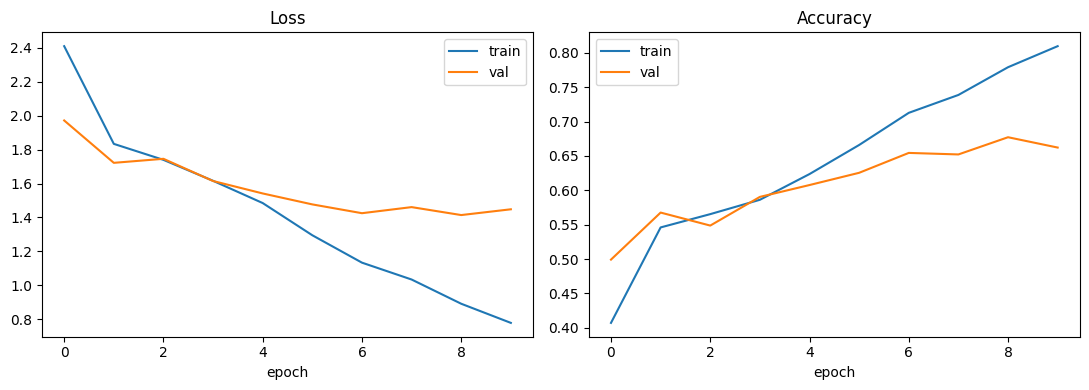

true topic:  3   predicted:  4
true topic: 10   predicted:  1
true topic:  1   predicted: 11
true topic:  4   predicted:  4
true topic:  4   predicted: 13


In [2]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout, Input
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.datasets import reuters
import matplotlib.pyplot as plt
print("TensorFlow:", tf.__version__)
num_words = 10000     # TODO (Q1a): 10000
maxlen    = 200     # TODO (Q1a): 200

(X_train, y_train), (X_test, y_test) = reuters.load_data(num_words=num_words, test_split=0.2)

# Q1b) pad both sets
X_train = pad_sequences(X_train, maxlen=maxlen)   # TODO (Q1b): maxlen
X_test  = pad_sequences(X_test,  maxlen=maxlen)   # TODO (Q1b): maxlen

# Q1c) how many topic classes? (labels are integers 0..45)
num_classes = int(max(y_train)) + 1   # TODO (Q1c): int(max(y_train)) + 1
print("X_train:", X_train.shape, " classes:", num_classes)
assert X_train.shape[1] == 200, "pad reviews to length 200"
assert num_classes == 46, "Reuters has 46 topic classes"
print("Task 1 looks correct ✔")
model = Sequential()
model.add(Input(shape=(maxlen,)))

# Q2a) Embedding
model.add(Embedding(input_dim=num_words, output_dim=128))   # TODO (Q2a): num_words, 128

# Q2b) Bidirectional LSTM -> one summary vector
model.add(Bidirectional(LSTM(64, return_sequences=False)))   # TODO (Q2b): 64, False

model.add(Dropout(0.5))

# Q2c) Output: one neuron PER CLASS with softmax
model.add(Dense(num_classes, activation='softmax'))   # TODO (Q2c): num_classes, 'softmax'

model.summary()
# Q3a) compile for integer multi-class labels
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',              # TODO (Q3a): 'sparse_categorical_crossentropy'
              metrics=['accuracy'])

# Q3b) train with a validation split
history = model.fit(X_train, y_train,
                    validation_split=0.2,   # TODO (Q3b): 0.2
                    epochs=10,             # TODO (Q3b): 10
                    batch_size=64)         # TODO (Q3b): 64
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test accuracy: {accuracy*100:.2f}%")   # expect ~ 65-72%

plt.figure(figsize=(11,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')      # TODO (Q4a): 'val_loss'
plt.title('Loss'); plt.xlabel('epoch'); plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')      # TODO (Q4b): 'val_accuracy'
plt.title('Accuracy'); plt.xlabel('epoch'); plt.legend()
plt.tight_layout(); plt.show()
probs = model.predict(X_test[:5], verbose=0)   # shape (5, 46)

# Q5) pick the most likely topic for each review
pred_classes = np.argmax(probs, axis=1)   # TODO (Q5): np.argmax(probs, axis=1)

for i in range(5):
    print(f"true topic: {y_test[i]:2d}   predicted: {pred_classes[i]:2d}")